<a href="https://colab.research.google.com/github/laxhidualopez06/Py---1--Laxhidua/blob/main/M_A_Reporte.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

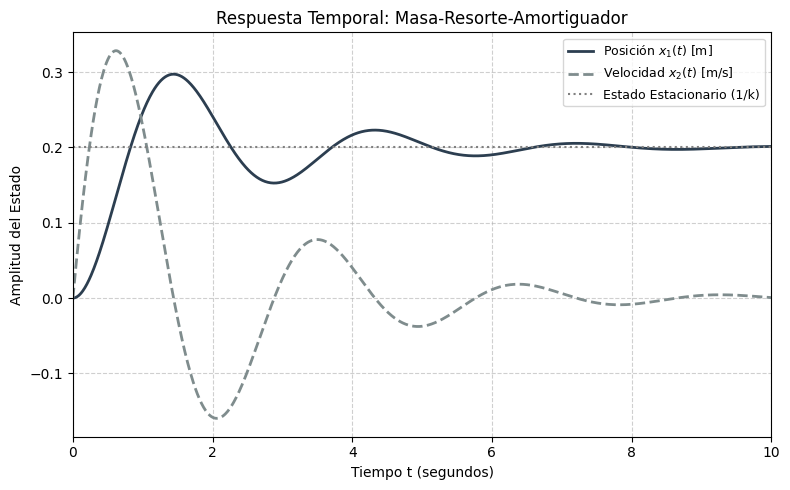

Eigenvalores del sistema: [-0.5+2.17944947j -0.5-2.17944947j]


In [1]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt

# 1. Definición de parámetros físicos (Ajustados a la gráfica del profesor)
m = 1.0  # Masa (kg)
c = 1.0  # Coeficiente de amortiguamiento viscoso (Ns/m)
k = 5.0  # Constante de rigidez del resorte (N/m)

# 2. Matrices del Espacio de Estados
# x1 = posición, x2 = velocidad
A = np.array([[0, 1],
              [-k/m, -c/m]])

B = np.array([[0],
              [1/m]])

# Matriz C para observar la posición (aunque graficaremos ambos estados)
C = np.array([[1, 0]])
D = np.array([[0]])

# 3. Creación del sistema dinámico
sys = signal.StateSpace(A, B, C, D)

# 4. Vector de tiempo y señal de entrada (Escalón unitario)
t = np.linspace(0, 10, 1000) # De 0 a 10 segundos para coincidir con la diapositiva
u = np.ones_like(t)          # Fuerza u(t) = 1 N constante

# 5. Simulación de la respuesta temporal
t_out, y_out, x_out = signal.lsim(sys, U=u, T=t)

# 6. Configuración de la gráfica (Estilo profesional IEEE)
plt.figure(figsize=(8, 5))

# x_out[:, 0] es el estado x1 (posición), x_out[:, 1] es el estado x2 (velocidad)
plt.plot(t_out, x_out[:, 0], '-', color='#2c3e50', linewidth=2, label='Posición $x_1(t)$ [m]')
plt.plot(t_out, x_out[:, 1], '--', color='#7f8c8d', linewidth=2, label='Velocidad $x_2(t)$ [m/s]')

# Línea del estado estacionario
plt.axhline(y=1/k, color='gray', linestyle=':', linewidth=1.5, label='Estado Estacionario (1/k)')

# Detalles estéticos de la gráfica
plt.title('Respuesta Temporal: Masa-Resorte-Amortiguador', fontsize=12)
plt.xlabel('Tiempo t (segundos)', fontsize=10)
plt.ylabel('Amplitud del Estado', fontsize=10)
plt.xlim(0, 10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right', fontsize=9)

# Mostrar y guardar
plt.tight_layout()
plt.savefig('respuesta_temporal_sistema.png', dpi=300) # Guarda la imagen en alta calidad
plt.show()

# 7. Imprimir eigenvalores para el análisis del reporte
eigenvalores, _ = np.linalg.eig(A)
print(f"Eigenvalores del sistema: {eigenvalores}")